# Phase 6 : Visualisation et Storytelling

## Objectif

Cette phase transforme les résultats de l'EDA analytique en visualisations
claires, cohérentes et directement interprétables.

Les graphiques ne cherchent plus à explorer les données mais à communiquer
les principaux enseignements du projet.

Le récit suit cinq étapes :

1. mesurer la stabilité de la production offensive ;
2. comprendre l'effet de la phase de carrière ;
3. identifier les signaux individuels les plus associés aux points futurs ;
4. comparer ces signaux au contexte collectif ;
5. montrer que le poste décrit surtout le profil statistique du joueur.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


PROJECT_ROOT = Path.cwd()

PHASE5_DIR = (
    PROJECT_ROOT
    / "reports"
    / "phase5_eda"
)

FIG_DIR = (
    PROJECT_ROOT
    / "reports"
    / "phase6_visualisations"
)


FIG_DIR.mkdir(
    parents=True,
    exist_ok=True
)


PERIOD = "1996-97 à 2022-23"

SOURCE_TEXT = (
    "Source : NBA API | "
    + PERIOD
)


plt.rcParams.update({
    "figure.figsize": (10, 6),
    "font.size": 11,
    "axes.titlesize": 15,
    "axes.labelsize": 11,
    "legend.fontsize": 10,
})

In [2]:
# Chargement des résultats de la Phase 5

q1_evolution = pd.read_csv(
    PHASE5_DIR
    / "Q1_distribution_evolution.csv"
)

q2_age = pd.read_csv(
    PHASE5_DIR
    / "Q2_analyse_age.csv"
)

q2_age_curve = pd.read_csv(
    PHASE5_DIR
    / "Q2_evolution_age_exact.csv"
)

q3_correlations = pd.read_csv(
    PHASE5_DIR
    / "Q3_correlations_role.csv"
)

q4_correlations = pd.read_csv(
    PHASE5_DIR
    / "Q4_correlations_contexte_equipe.csv"
)

q5_profile = pd.read_csv(
    PHASE5_DIR
    / "Q5_profils_postes.csv"
)

q5_future = pd.read_csv(
    PHASE5_DIR
    / "Q5_production_future_postes.csv"
)


print(
    "Résultats Phase 5 chargés."
)

Résultats Phase 5 chargés.


## Visualisation 1 : une production persistante mais loin d'être figée

### Objectif

Montrer immédiatement l'ampleur du phénomène que le modèle devra prédire.

### Insight

50,53 % des joueur-saisons restent à moins de 2 points de leur niveau précédent,
mais 49,47 % progressent ou régressent d'au moins 2 points.

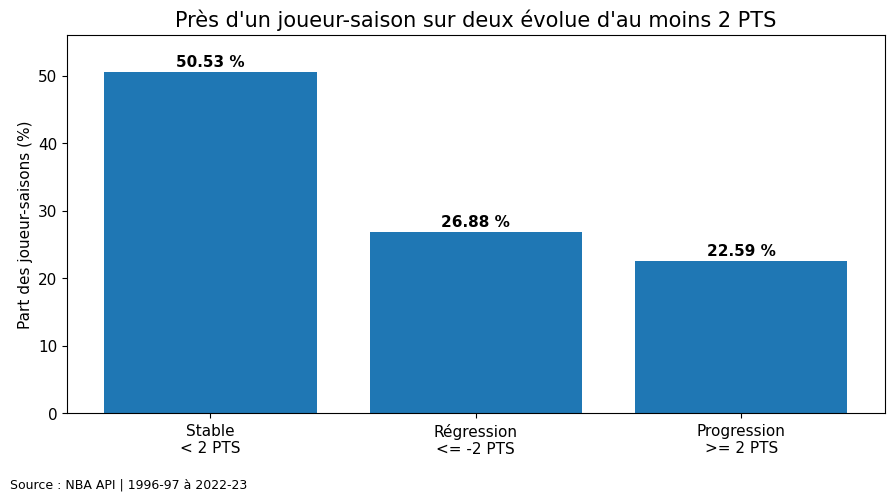

In [3]:
# Répartition des évolutions entre N et N+1

plot_q1 = q1_evolution.copy()


label_map = {
    "Stable : |variation| < 2 PTS":
        "Stable\n< 2 PTS",

    "Stable à ±2 PTS":
        "Stable\n< 2 PTS",

    "Progression >= 2 PTS":
        "Progression\n>= 2 PTS",

    "Régression <= -2 PTS":
        "Régression\n<= -2 PTS",

    "Régression >= 2 PTS":
        "Régression\n<= -2 PTS",
}


plot_q1[
    "label"
] = (
    plot_q1[
        "profil"
    ]
    .replace(
        label_map
    )
)


plt.figure(
    figsize=(9, 5)
)


bars = plt.bar(
    plot_q1[
        "label"
    ],
    plot_q1[
        "pourcentage"
    ]
)


for bar, value in zip(
    bars,
    plot_q1[
        "pourcentage"
    ]
):

    plt.text(
        bar.get_x()
        + bar.get_width() / 2,
        bar.get_height() + 0.8,
        f"{value:.2f} %",
        ha="center",
        fontweight="bold"
    )


plt.ylim(
    0,
    56
)

plt.ylabel(
    "Part des joueur-saisons (%)"
)

plt.title(
    "Près d'un joueur-saison sur deux évolue d'au moins 2 PTS"
)

plt.figtext(
    0.01,
    0.01,
    SOURCE_TEXT,
    fontsize=9
)

plt.tight_layout(
    rect=[
        0,
        0.04,
        1,
        1,
    ]
)


plt.savefig(
    FIG_DIR
    / "01_stabilite_production.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

## Visualisation 2 : la progression s'inverse avec l'âge

### Objectif

Montrer comment la variation moyenne des points évolue avec l'âge.

### Insight

La progression est forte chez les jeunes joueurs, devient proche de zéro autour
de 25-26 ans puis devient globalement négative.

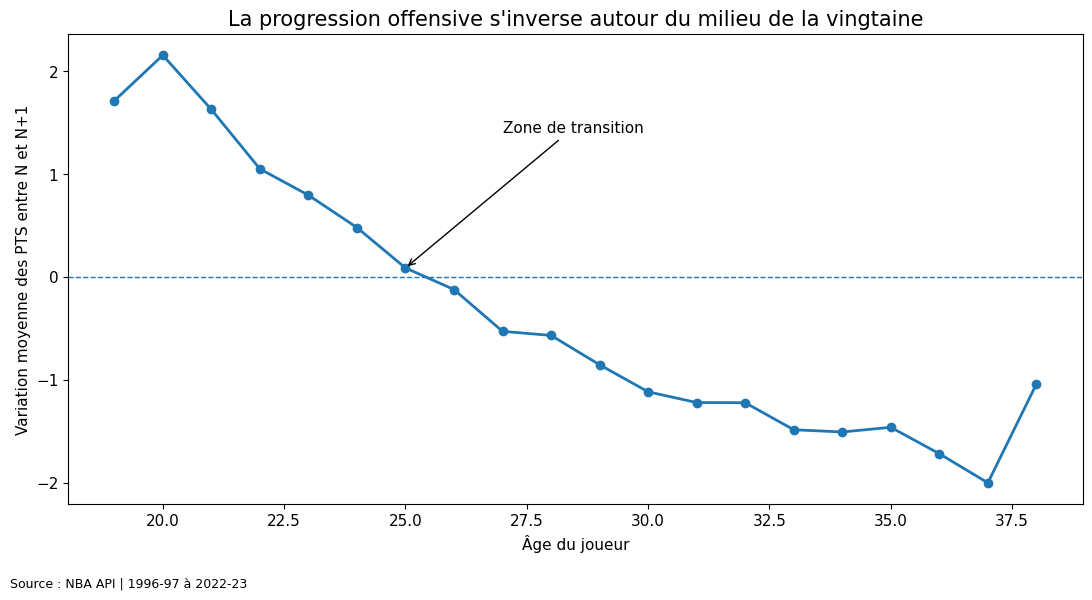

In [4]:
# Evolution des points selon l'âge

plt.figure(
    figsize=(11, 6)
)


plt.plot(
    q2_age_curve[
        "AGE"
    ],
    q2_age_curve[
        "variation_moyenne"
    ],
    marker="o",
    linewidth=2
)


plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)


plt.xlabel(
    "Âge du joueur"
)

plt.ylabel(
    "Variation moyenne des PTS entre N et N+1"
)

plt.title(
    "La progression offensive s'inverse autour du milieu de la vingtaine"
)


plt.annotate(
    "Zone de transition",
    xy=(
        25,
        q2_age_curve.loc[
            q2_age_curve[
                "AGE"
            ] == 25,
            "variation_moyenne"
        ].iloc[0]
    ),
    xytext=(
        27,
        1.4
    ),
    arrowprops={
        "arrowstyle": "->"
    }
)


plt.figtext(
    0.01,
    0.01,
    SOURCE_TEXT,
    fontsize=9
)


plt.tight_layout(
    rect=[
        0,
        0.04,
        1,
        1,
    ]
)


plt.savefig(
    FIG_DIR
    / "02_cycle_carriere_age.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

## Visualisation 3 : le rôle offensif est fortement associé aux points futurs

### Objectif

Comparer les trois principales dimensions du rôle offensif du joueur.

### Insight

Le volume de tirs est le signal individuel le plus fortement associé à
`pts_next_season`, avec une corrélation de 0,838.

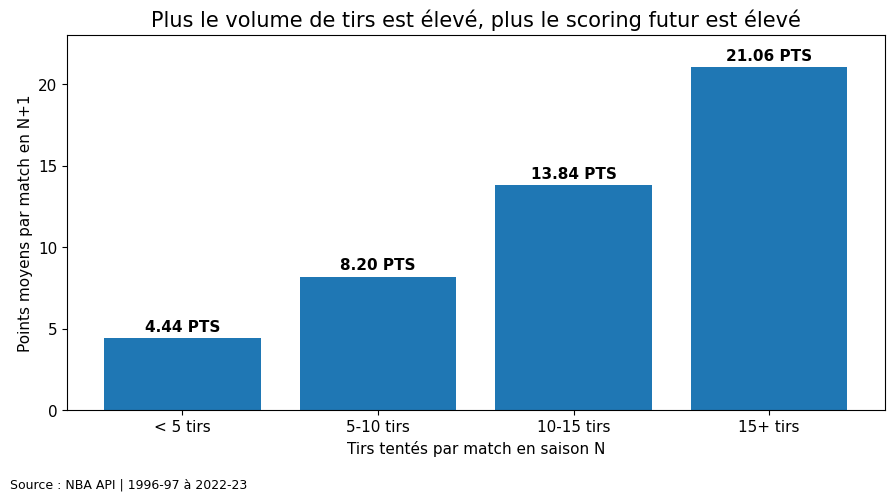

In [11]:
# Production future selon le volume de tirs

q3_fga = pd.read_csv(
    PHASE5_DIR
    / "Q3_analyse_tirs.csv"
)


plt.figure(
    figsize=(9, 5)
)


bars = plt.bar(
    q3_fga[
        "FGA_GROUP"
    ],
    q3_fga[
        "pts_n1_moyen"
    ]
)


for bar, value in zip(
    bars,
    q3_fga[
        "pts_n1_moyen"
    ]
):

    plt.text(
        bar.get_x()
        + bar.get_width() / 2,
        bar.get_height() + 0.4,
        f"{value:.2f} PTS",
        ha="center",
        fontweight="bold"
    )


plt.ylim(
    0,
    23
)

plt.xlabel(
    "Tirs tentés par match en saison N"
)

plt.ylabel(
    "Points moyens par match en N+1"
)

plt.title(
    "Plus le volume de tirs est élevé, plus le scoring futur est élevé"
)


plt.figtext(
    0.01,
    0.01,
    SOURCE_TEXT,
    fontsize=9
)


plt.tight_layout(
    rect=[
        0,
        0.04,
        1,
        1,
    ]
)


plt.savefig(
    FIG_DIR
    / "03_volume_tirs_scoring_futur.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

## Visualisation 4 : les caractéristiques individuelles dominent le contexte collectif

### Objectif

Comparer les meilleurs signaux individuels et les meilleurs signaux provenant
de l'équipe.

### Insight

La meilleure variable collective possède une corrélation très faible par rapport
aux statistiques individuelles du joueur.

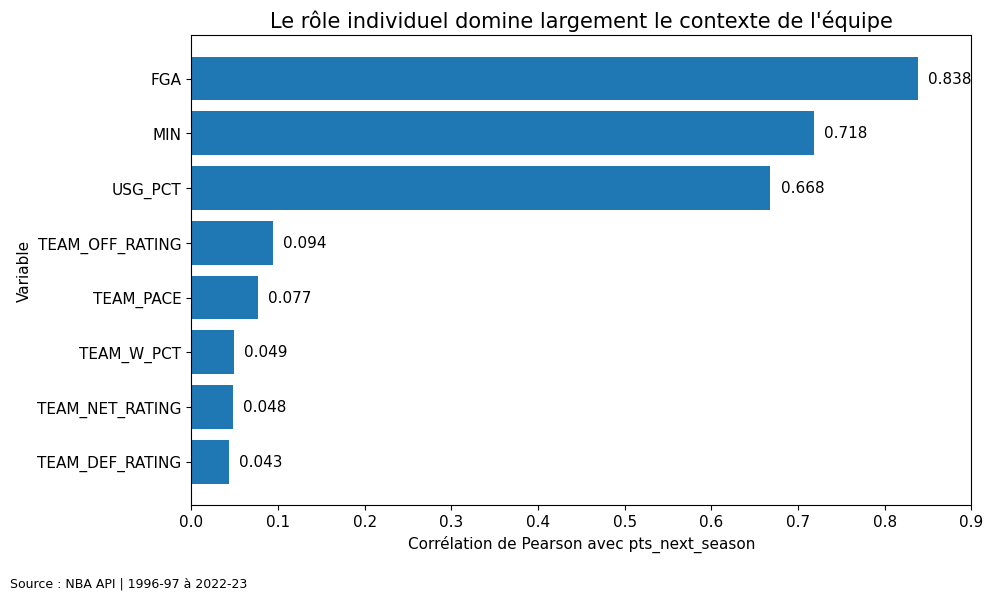

In [6]:
# Comparaison des meilleurs signaux individuels et collectifs

individual_signals = (
    q3_correlations[
        [
            "feature",
            "pearson_cible",
        ]
    ]
    .copy()
)


team_signals = (
    q4_correlations[
        [
            "feature",
            "pearson_cible",
        ]
    ]
    .copy()
)


individual_signals[
    "type"
] = "Individuel"

team_signals[
    "type"
] = "Équipe"


signal_comparison = pd.concat(
    [
        individual_signals,
        team_signals,
    ],
    ignore_index=True
)


signal_comparison = (
    signal_comparison
    .sort_values(
        "pearson_cible",
        ascending=False
    )
)


plt.figure(
    figsize=(10, 6)
)


bars = plt.barh(
    signal_comparison[
        "feature"
    ],
    signal_comparison[
        "pearson_cible"
    ]
)


plt.gca().invert_yaxis()


for bar, value in zip(
    bars,
    signal_comparison[
        "pearson_cible"
    ]
):

    plt.text(
        value + 0.012,
        bar.get_y()
        + bar.get_height() / 2,
        f"{value:.3f}",
        va="center"
    )


plt.xlim(
    0,
    0.9
)

plt.xlabel(
    "Corrélation de Pearson avec pts_next_season"
)

plt.ylabel(
    "Variable"
)

plt.title(
    "Le rôle individuel domine largement le contexte de l'équipe"
)


plt.figtext(
    0.01,
    0.01,
    SOURCE_TEXT,
    fontsize=9
)


plt.tight_layout(
    rect=[
        0,
        0.04,
        1,
        1,
    ]
)


plt.savefig(
    FIG_DIR
    / "04_individuel_vs_equipe.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

## Visualisation 5 : chaque poste possède un profil statistique distinct

### Objectif

Comparer les styles statistiques moyens des Guards, Forwards et Centers.

### Insight

Les Guards dominent sur les passes et les tirs à trois points, tandis que les
Centers se distinguent par les rebonds et l'efficacité.

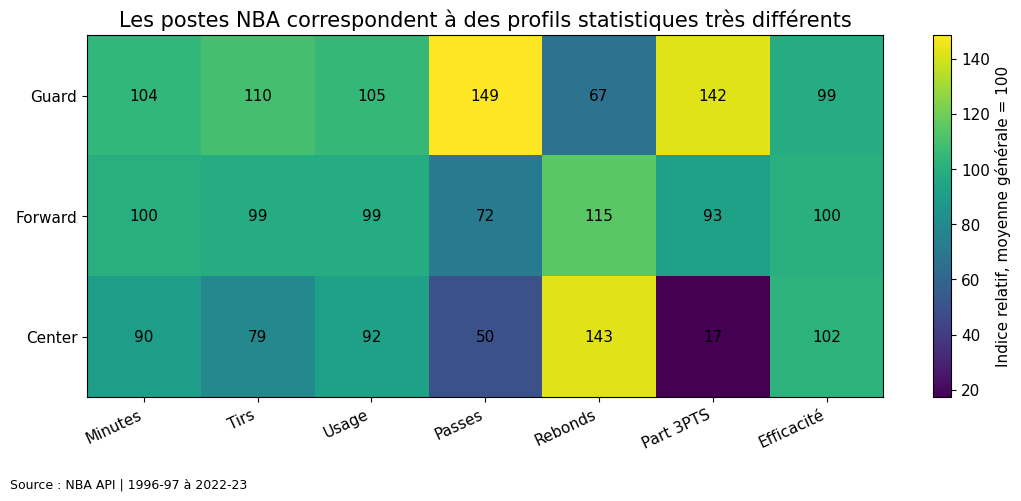

In [7]:
# Construction des indices relatifs

position_data = (
    q5_profile
    .set_index(
        "POSITION_PRIMARY"
    )
)


profile_columns = {
    "minutes": "Minutes",
    "tirs": "Tirs",
    "usage": "Usage",
    "passes": "Passes",
    "rebonds": "Rebonds",
    "part_tirs_3pts": "Part 3PTS",
    "efficacite": "Efficacité",
}


overall_values = (
    position_data[
        list(
            profile_columns.keys()
        )
    ]
    .mul(
        position_data[
            "joueur_saisons"
        ],
        axis=0
    )
    .sum()
    / position_data[
        "joueur_saisons"
    ].sum()
)


profile_index = (
    position_data[
        list(
            profile_columns.keys()
        )
    ]
    .div(
        overall_values
    )
    * 100
)


heatmap_data = (
    profile_index
    .to_numpy()
)


fig, ax = plt.subplots(
    figsize=(11, 5)
)


image = ax.imshow(
    heatmap_data,
    aspect="auto"
)


ax.set_xticks(
    np.arange(
        len(
            profile_columns
        )
    )
)

ax.set_xticklabels(
    list(
        profile_columns.values()
    ),
    rotation=25,
    ha="right"
)


ax.set_yticks(
    np.arange(
        len(
            profile_index.index
        )
    )
)

ax.set_yticklabels(
    profile_index.index
)


for i in range(
    heatmap_data.shape[0]
):

    for j in range(
        heatmap_data.shape[1]
    ):

        ax.text(
            j,
            i,
            f"{heatmap_data[i, j]:.0f}",
            ha="center",
            va="center"
        )


plt.colorbar(
    image,
    label="Indice relatif, moyenne générale = 100"
)


plt.title(
    "Les postes NBA correspondent à des profils statistiques très différents"
)


plt.figtext(
    0.01,
    0.01,
    SOURCE_TEXT,
    fontsize=9
)


plt.tight_layout(
    rect=[
        0,
        0.05,
        1,
        1,
    ]
)


plt.savefig(
    FIG_DIR
    / "05_profils_postes.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

## Visualisation 6 : le poste influence le niveau moyen mais peu l'évolution

### Objectif

Comparer la production moyenne actuelle et future des trois postes principaux.

### Insight

Les Guards affichent le niveau moyen de scoring le plus élevé, mais les trois
postes présentent seulement de faibles variations entre N et N+1.

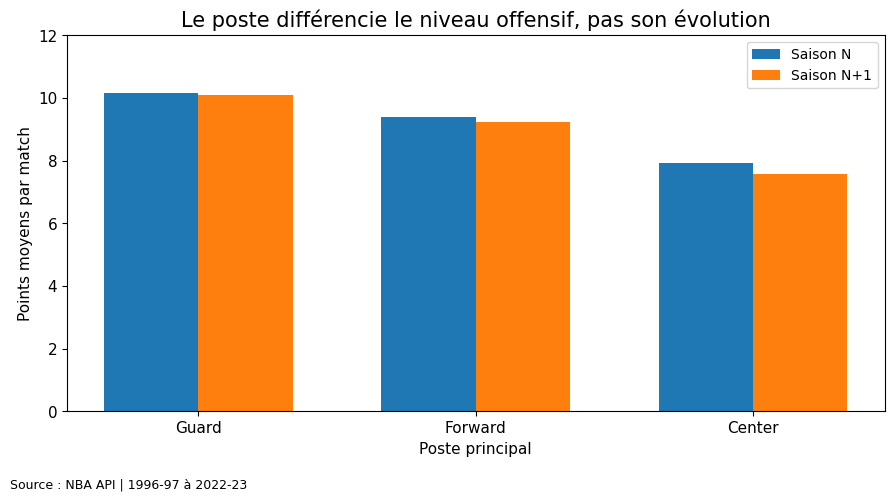

In [8]:
# Points moyens N et N+1 par poste

position_order = [
    "Guard",
    "Forward",
    "Center",
]


plot_position = (
    q5_future
    .set_index(
        "POSITION_PRIMARY"
    )
    .reindex(
        position_order
    )
    .reset_index()
)


x = np.arange(
    len(
        plot_position
    )
)

width = 0.34


plt.figure(
    figsize=(9, 5)
)


plt.bar(
    x - width / 2,
    plot_position[
        "pts_n_moyen"
    ],
    width,
    label="Saison N"
)

plt.bar(
    x + width / 2,
    plot_position[
        "pts_n1_moyen"
    ],
    width,
    label="Saison N+1"
)


plt.xticks(
    x,
    plot_position[
        "POSITION_PRIMARY"
    ]
)

plt.ylim(
    0,
    12
)

plt.ylabel(
    "Points moyens par match"
)

plt.xlabel(
    "Poste principal"
)

plt.title(
    "Le poste différencie le niveau offensif, pas son évolution"
)

plt.legend()


plt.figtext(
    0.01,
    0.01,
    SOURCE_TEXT,
    fontsize=9
)


plt.tight_layout(
    rect=[
        0,
        0.04,
        1,
        1,
    ]
)


plt.savefig(
    FIG_DIR
    / "06_scoring_par_poste.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

## Visualisation 7 : continuité du scoring

Le nuage de points montre que les points en saison N restent fortement liés aux
points en N+1.

La majorité des joueurs reste proche de la diagonale, mais certaines fortes
progressions et régressions subsistent.

**Insight :** `PTS` est un repère important pour la prédiction, mais ne suffit
pas seul à expliquer la saison suivante.

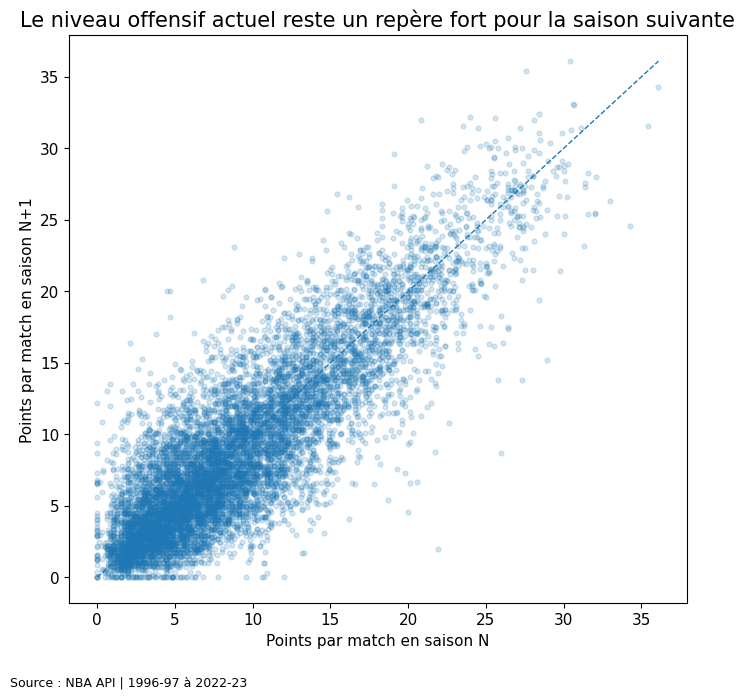

In [ ]:
# Continuité de la production offensive

supervised_dataset = pd.read_parquet(
    PROJECT_ROOT
    / "data"
    / "processed"
    / "nba_player_season_supervised.parquet"
)


plt.figure(
    figsize=(7, 7)
)


plt.scatter(
    supervised_dataset[
        "PTS"
    ],
    supervised_dataset[
        "pts_next_season"
    ],
    alpha=0.18,
    s=12
)


max_pts = max(
    supervised_dataset[
        "PTS"
    ].max(),
    supervised_dataset[
        "pts_next_season"
    ].max()
)


plt.plot(
    [
        0,
        max_pts,
    ],
    [
        0,
        max_pts,
    ],
    linestyle="--",
    linewidth=1
)


plt.xlabel(
    "Points par match en saison N"
)

plt.ylabel(
    "Points par match en saison N+1"
)

plt.title(
    "Le niveau offensif actuel reste un repère fort pour la saison suivante"
)


plt.figtext(
    0.01,
    0.01,
    SOURCE_TEXT,
    fontsize=9
)


plt.tight_layout(
    rect=[
        0,
        0.04,
        1,
        1,
    ]
)


plt.savefig(
    FIG_DIR
    / "07_continuite_scoring.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

## Dashboard de synthèse

Cette vue rassemble les principaux enseignements de l'EDA analytique.

Elle sert de transition entre l'analyse descriptive et la future modélisation.

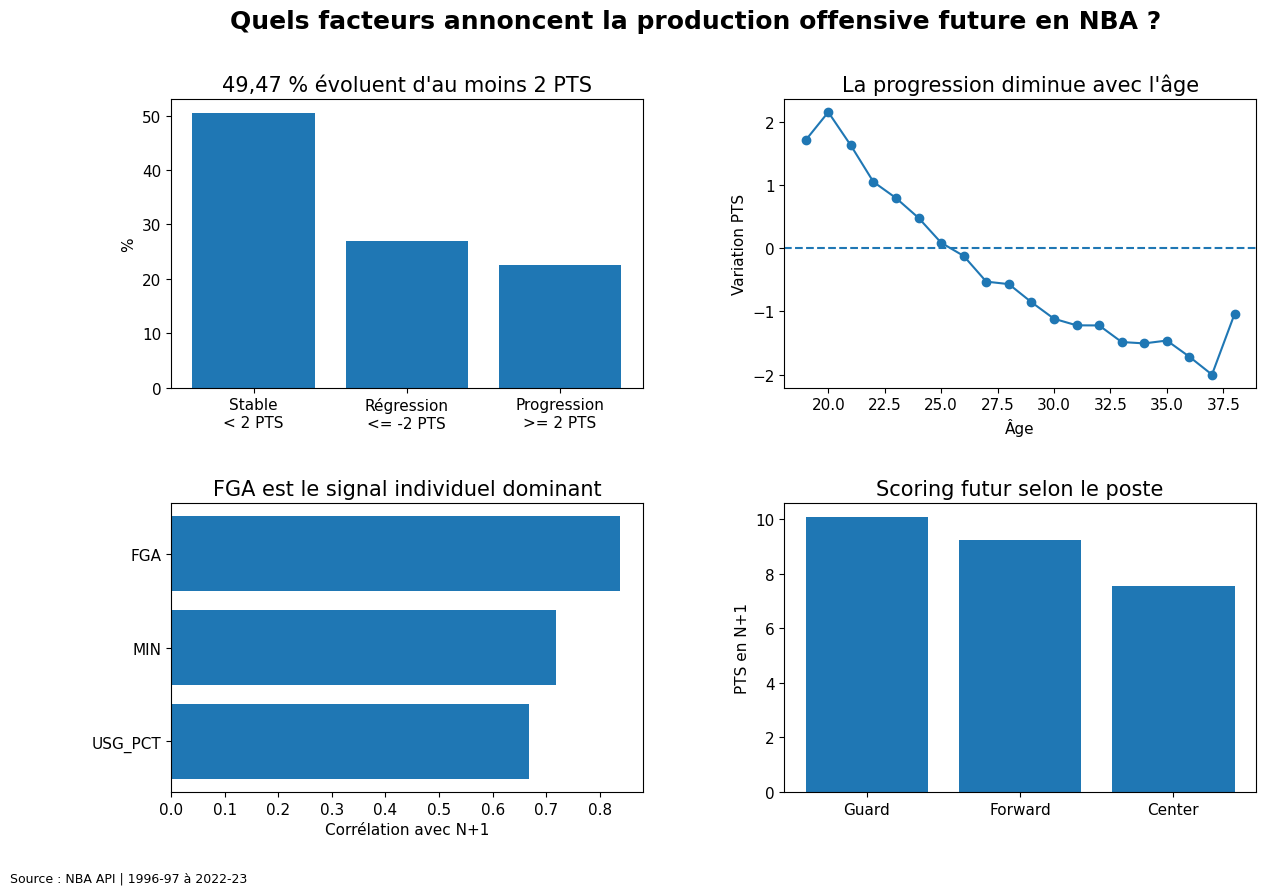

In [10]:
# Dashboard de synthèse

fig = plt.figure(
    figsize=(14, 9)
)


grid = fig.add_gridspec(
    2,
    2,
    hspace=0.4,
    wspace=0.3
)


# Q1
ax1 = fig.add_subplot(
    grid[
        0,
        0
    ]
)


ax1.bar(
    plot_q1[
        "label"
    ],
    plot_q1[
        "pourcentage"
    ]
)

ax1.set_title(
    "49,47 % évoluent d'au moins 2 PTS"
)

ax1.set_ylabel(
    "%"
)


# Q2
ax2 = fig.add_subplot(
    grid[
        0,
        1
    ]
)


ax2.plot(
    q2_age_curve[
        "AGE"
    ],
    q2_age_curve[
        "variation_moyenne"
    ],
    marker="o"
)

ax2.axhline(
    0,
    linestyle="--"
)

ax2.set_title(
    "La progression diminue avec l'âge"
)

ax2.set_xlabel(
    "Âge"
)

ax2.set_ylabel(
    "Variation PTS"
)


# Q3
ax3 = fig.add_subplot(
    grid[
        1,
        0
    ]
)


ax3.barh(
    role_plot[
        "feature"
    ],
    role_plot[
        "pearson_cible"
    ]
)

ax3.set_title(
    "FGA est le signal individuel dominant"
)

ax3.set_xlabel(
    "Corrélation avec N+1"
)


# Q5
ax4 = fig.add_subplot(
    grid[
        1,
        1
    ]
)


ax4.bar(
    plot_position[
        "POSITION_PRIMARY"
    ],
    plot_position[
        "pts_n1_moyen"
    ]
)

ax4.set_title(
    "Scoring futur selon le poste"
)

ax4.set_ylabel(
    "PTS en N+1"
)


fig.suptitle(
    "Quels facteurs annoncent la production offensive future en NBA ?",
    fontsize=18,
    fontweight="bold"
)


fig.text(
    0.01,
    0.01,
    SOURCE_TEXT,
    fontsize=9
)


plt.savefig(
    FIG_DIR
    / "08_dashboard_synthese.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

## Fil narratif

### 1. Contexte

La production offensive d'un joueur NBA présente une forte continuité d'une
saison à la suivante.

### 2. Tension

Cette continuité n'est cependant pas suffisante : près de la moitié des
joueur-saisons évoluent d'au moins 2 points par match.

Il devient donc nécessaire d'identifier les facteurs associés à la production
future.

### 3. Premiers facteurs explicatifs

La phase de carrière apporte un premier signal important.

Les jeunes joueurs progressent beaucoup plus fréquemment, tandis que la
régression devient dominante avec l'âge et l'expérience.

### 4. Signal principal

Le rôle offensif actuel du joueur constitue le signal le plus fort observé.

Le volume de tirs, le temps de jeu et l'usage sont fortement associés aux
points de la saison suivante.

### 5. Mise en perspective

Le contexte collectif de l'équipe apporte beaucoup moins d'information directe
que les caractéristiques individuelles.

Le poste distingue clairement différents profils de jeu, mais son effet isolé
sur la production future reste faible.

### 6. Résolution

Le futur modèle devra donc principalement combiner :

- production actuelle et historique ;
- rôle offensif ;
- âge et expérience.

Le poste et le contexte collectif pourront être utilisés comme informations
complémentaires.

### 7. Action

La Phase 7 devra vérifier si ces hypothèses issues de l'EDA se retrouvent dans
les performances et les importances des variables du modèle.

## Questions de réflexion

### 1. Quelle visualisation est la plus impactante ?

La comparaison entre les variables individuelles et collectives est
particulièrement impactante car elle montre immédiatement l'écart entre
l'importance du rôle du joueur et celle du contexte de son équipe.

### 2. Les graphiques sont-ils compréhensibles sans explication orale ?

Les titres ont été formulés comme des messages plutôt que comme de simples
descriptions. Les axes, unités, sources et périodes sont également indiqués
afin que chaque graphique puisse être interprété indépendamment.

### 3. Quelle visualisation pourrait être améliorée ?

La représentation des profils par poste pourrait être enrichie avec une
visualisation interactive permettant d'afficher les valeurs exactes et de
sélectionner les statistiques.

### 4. Quel est le fil rouge du récit ?

Le récit part de l'incertitude à prédire, identifie progressivement les facteurs
associés à la performance future, puis hiérarchise ces informations pour
préparer la modélisation Machine Learning.

## Utilisation de l'IA

L'IA a été utilisée pour :

- sélectionner les visualisations les plus adaptées aux insights de Phase 5 ;
- réduire les graphiques exploratoires à un ensemble de visualisations
  réellement utiles au storytelling ;
- améliorer les titres afin qu'ils expriment directement le message principal ;
- structurer le récit du général vers les facteurs explicatifs ;
- vérifier les risques de mauvaises interprétations visuelles ;
- organiser la vue de synthèse.

Les graphiques reposent exclusivement sur les résultats calculés et validés
pendant l'EDA analytique.

## Conclusion de la Phase 6

Sept visualisations principales et une vue de synthèse ont été construites à
partir des résultats de l'EDA analytique.

Le storytelling met en évidence trois enseignements principaux :

1. la production offensive possède une forte continuité mais reste suffisamment
   variable pour justifier une approche prédictive ;

2. les caractéristiques individuelles, notamment le rôle offensif et la phase
   de carrière, constituent les principaux signaux associés aux points futurs ;

3. le poste et le contexte collectif apportent surtout des informations
   complémentaires.

Les visualisations sont maintenant prêtes à être utilisées pour la
documentation et la soutenance.

La prochaine étape consiste à vérifier ces hypothèses par la modélisation
Machine Learning.